# Phase 25 — Final Consolidation

**Diabetic Foot Thermography Research Project**

This notebook is the single consolidation point for 25 phases of
experimentation and diagnostics. It performs **no modeling and no
retraining** — it only reads result files that earlier phases already
saved to disk, and produces:

1. One master model-comparison table (`results/master_model_comparison.csv`)
2. Four new summary figures (`fig1`–`fig4`)
3. A complete figure index covering all 8 figures now on disk (`results/figure_index.json`)
4. A paper-section mapping (`results/paper_section_mapping.json`)
5. A final plain-language project recap

**Which results are FINAL (used below) vs. SUPERSEDED (not used):**

| Phase | Status | Note |
|---|---|---|
| 11 | ❌ superseded | single-split DualBranchGAT result, superseded by Phase 13's CV result |
| 13 | ✅ final | DualBranchGAT, cross-validated — the primary model result |
| 14 | ✅ final | 4 TCI baselines |
| 16 | ❌ superseded | 2-way fusion, superseded by Phase 24's 3-way fusion |
| 17 | ✅ final | structure ablation (4 edge-construction variants) |
| 18 | ✅ final | attention / region-importance interpretability |
| 19 | ✅ final | multi-seed robustness (4 seeds) |
| 20 | ✅ final | uncertainty–error linkage & rejection curve |
| 22 | ✅ final | age-overlap ("hard" vs "easy" subset) confound check |
| 23 | ✅ final | bilateral graph — reported as a deliberate, honest null result |
| 24 | ✅ final | **headline model**: final 3-way fusion |
| 25 | ✅ final | diagnostic assets (training curve, confusion matrix, PR curve, calibration) |

Only phases marked ✅ final are used in the master table below.


In [1]:
\
# ===========================================================================
# IMPORTS & GLOBAL SETUP
# ===========================================================================
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore")

# Use Path throughout (Windows-compatible). All paths are relative to the
# notebook's working directory, which should be the project root when run
# in VS Code (i.e. the folder that contains "results/").
BASE_DIR = Path("results")
FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Running log of anything that went wrong or looked off, surfaced again in
# the final summary cell so nothing gets silently lost.
issues = []


def log_issue(msg):
    issues.append(msg)
    print(f"    [ISSUE] {msg}")


def safe_read_csv(path):
    '''Read a CSV, returning None (and logging) instead of raising.'''
    path = Path(path)
    if not path.exists():
        log_issue(f"Missing file: {path} — sections depending on it will be skipped.")
        return None
    try:
        return pd.read_csv(path)
    except Exception as e:
        log_issue(f"Could not read {path}: {e}")
        return None


def safe_read_json(path):
    '''Read a JSON file, returning None (and logging) instead of raising.'''
    path = Path(path)
    if not path.exists():
        log_issue(f"Missing file: {path} — sections depending on it will be skipped.")
        return None
    try:
        with open(path, "r") as f:
            return json.load(f)
    except Exception as e:
        log_issue(f"Could not read {path}: {e}")
        return None


def find_col(df, candidates):
    '''Case/underscore-insensitive column lookup. Returns the real column
    name from df, or None if nothing matches any candidate.'''
    if df is None:
        return None
    norm = {c.lower().replace(" ", "_"): c for c in df.columns}
    for cand in candidates:
        key = cand.lower().replace(" ", "_")
        if key in norm:
            return norm[key]
    return None


def get_key(d, candidates, default=None):
    '''Case-insensitive dict key lookup across a list of candidate names.'''
    if not isinstance(d, dict):
        return default
    norm = {k.lower(): k for k in d.keys()}
    for cand in candidates:
        key = cand.lower()
        if key in norm:
            return d[norm[key]]
    return default


def fmt_mean_std(mean, std, label="fold mean ± std"):
    if mean is None:
        return "n/a"
    if std is None or (isinstance(std, float) and np.isnan(std)):
        return f"{mean:.3f} (pooled value)"
    return f"{mean:.3f} ± {std:.3f} ({label})"


def roc_curve_np(y_true, y_score):
    '''Minimal numpy-only ROC curve (no sklearn — this notebook adds no
    new dependencies). Returns fpr, tpr sorted by ascending threshold.'''
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    order = np.argsort(-y_score)
    y_true = y_true[order]
    y_score = y_score[order]
    n_pos = y_true.sum()
    n_neg = len(y_true) - n_pos
    if n_pos == 0 or n_neg == 0:
        return np.array([0, 1]), np.array([0, 1]), np.array([1, 0])
    tps = np.cumsum(y_true)
    fps = np.cumsum(1 - y_true)
    # keep only points where score changes (thresholds)
    distinct = np.where(np.diff(y_score) != 0)[0]
    idx = np.r_[distinct, len(y_score) - 1]
    tpr = np.r_[0, tps[idx] / n_pos]
    fpr = np.r_[0, fps[idx] / n_neg]
    thresh = np.r_[y_score[0] + 1, y_score[idx]]
    return fpr, tpr, thresh


def auc_trapz(fpr, tpr):
    order = np.argsort(fpr)
    x = np.asarray(fpr)[order]
    y = np.asarray(tpr)[order]
    # np.trapz was removed in numpy>=2.0 in favor of np.trapezoid; support both.
    trapz_fn = getattr(np, "trapezoid", None) or np.trapz
    return float(trapz_fn(y, x))


print("Setup complete. BASE_DIR =", BASE_DIR.resolve())


Setup complete. BASE_DIR = C:\workstation\3RD YEAR\Diabetic_Foot\results


## 1. Setup — load every result file

Loads every file the master table and figures depend on. Each file is
loaded independently: if one is missing, we print exactly which one and
continue — only the section(s) that need it are skipped later, the rest
of the notebook still runs.


In [2]:
\
# ===========================================================================
# 1. SETUP: LOAD ALL RESULT FILES
# ===========================================================================
print("=" * 70)
print("SECTION 1 — LOADING RESULT FILES")
print("=" * 70)

FILES = {
    # Phase 13 — DualBranchGAT, cross-validated (primary result)
    "cv_fold_metrics":               ("csv",  BASE_DIR / "cv_fold_metrics.csv"),
    "cv_summary":                    ("json", BASE_DIR / "cv_summary.json"),
    # Phase 14 — TCI baselines
    "baseline_comparison":           ("csv",  BASE_DIR / "baseline_comparison.csv"),
    "baseline_pooled_predictions":   ("csv",  BASE_DIR / "baseline_pooled_predictions.csv"),
    # Phase 17 — structure ablation
    "structure_ablation_results":    ("csv",  BASE_DIR / "structure_ablation_results.csv"),
    # Phase 18 — attention / interpretability
    "attention_region_importance":   ("csv",  BASE_DIR / "attention_region_importance.csv"),
    "attention_group_comparison":    ("json", BASE_DIR / "attention_group_comparison.json"),
    # Phase 19 — multi-seed robustness
    "multiseed_robustness_results":  ("csv",  BASE_DIR / "multiseed_robustness_results.csv"),
    # Phase 20 — uncertainty
    "uncertainty_error_linkage":     ("csv",  BASE_DIR / "uncertainty_error_linkage.csv"),
    "uncertainty_rejection_vs_random": ("json", BASE_DIR / "uncertainty_rejection_vs_random.json"),
    # Phase 22 — age-overlap confound check
    "age_overlap_summary":           ("json", BASE_DIR / "age_overlap_summary.json"),
    # Phase 23 — bilateral graph (negative result)
    "bilateral_graph_results":       ("csv",  BASE_DIR / "bilateral_graph_results.csv"),
    # Phase 24 — final 3-way fusion (headline model)
    "final_fusion_polish":           ("csv",  BASE_DIR / "final_fusion_polish.csv"),
    "final_model_predictions":       ("csv",  BASE_DIR / "final_model_predictions.csv"),
    "final_fusion_polish_summary":   ("json", BASE_DIR / "final_fusion_polish_summary.json"),
    # Phase 25 — diagnostic assets (figures already on disk)
    "diagnostic_assets_summary":     ("json", BASE_DIR / "diagnostic_assets_summary.json"),
    "training_history_fold0":       ("json", BASE_DIR / "training_history_fold0.json"),
}

data = {}
loaded = {}
for key, (kind, path) in FILES.items():
    obj = safe_read_csv(path) if kind == "csv" else safe_read_json(path)
    data[key] = obj
    loaded[key] = obj is not None
    if obj is None:
        print(f"  [ ] {key:<32s} MISSING  ({path})")
    elif kind == "csv":
        print(f"  [x] {key:<32s} shape={obj.shape}")
    else:
        n_keys = len(obj) if isinstance(obj, dict) else len(obj) if isinstance(obj, list) else "?"
        print(f"  [x] {key:<32s} keys/len={n_keys}")

n_ok = sum(loaded.values())
print(f"\n{n_ok}/{len(FILES)} files loaded successfully.")
print("results/figures/ exists:", FIG_DIR.exists())


SECTION 1 — LOADING RESULT FILES
  [x] cv_fold_metrics                  shape=(5, 5)
  [x] cv_summary                       keys/len=9
  [x] baseline_comparison              shape=(5, 5)
  [x] baseline_pooled_predictions      shape=(167, 7)
  [x] structure_ablation_results       shape=(4, 14)
  [x] attention_region_importance      shape=(334, 7)
  [x] attention_group_comparison       keys/len=4
  [x] multiseed_robustness_results     shape=(4, 7)
  [x] uncertainty_error_linkage        shape=(167, 5)
  [x] uncertainty_rejection_vs_random  keys/len=7
  [x] age_overlap_summary              keys/len=6
  [x] bilateral_graph_results          shape=(1, 12)
  [x] final_fusion_polish              shape=(5, 5)
  [x] final_model_predictions          shape=(167, 7)
  [x] final_fusion_polish_summary      keys/len=7
  [x] diagnostic_assets_summary        keys/len=6
  [x] training_history_fold0           keys/len=49

17/17 files loaded successfully.
results/figures/ exists: True


## 2. Master model-comparison table

One row per distinct model/config evaluated across the project. Only
**final, non-superseded** results are included (see the status table
above — Phase 11 and Phase 16 are intentionally excluded).

`roc_auc_or_range` is a string: a fold-mean ± std where cross-validated
fold-level results are available, otherwise a single pooled value — the
column itself, and the code below, states which for every row.


In [3]:
\
# ===========================================================================
# 2. MASTER MODEL COMPARISON TABLE
# ===========================================================================
print("=" * 70)
print("SECTION 2 — MASTER MODEL COMPARISON TABLE")
print("=" * 70)

rows = []  # each: dict with model_name, category, roc_auc_or_range, balanced_accuracy, f1,
           # source_phase, source_file, _roc_sort (numeric, for sorting only)

CATEGORY_ORDER = ["primary", "tci_baseline", "structure_ablation", "bilateral", "final_headline"]


def add_from_fold_df(df, model_col, model_name_fixed, category, source_phase, source_file):
    '''Aggregate a fold-level dataframe (one row per fold) into a single
    master-table row with fold-mean ± std.'''
    if df is None:
        log_issue(f"Skipped '{model_name_fixed}' ({category}) — {source_file} not available.")
        return
    auc_col = find_col(df, ["roc_auc", "auc", "roc_auc_score"])
    bal_col = find_col(df, ["balanced_accuracy", "bal_acc", "balanced_acc"])
    f1_col = find_col(df, ["f1", "f1_score", "f1_macro"])
    if auc_col is None:
        log_issue(f"Skipped '{model_name_fixed}' ({category}) — no ROC AUC column found in {source_file}.")
        return
    sub = df
    if model_col and model_col in df.columns and model_name_fixed:
        sub = df[df[model_col].astype(str) == str(model_name_fixed)]
        if sub.empty:
            sub = df  # fall back to whole file if the exact name isn't found
    roc_mean, roc_std = sub[auc_col].mean(), sub[auc_col].std()
    bal_mean = sub[bal_col].mean() if bal_col else None
    f1_mean = sub[f1_col].mean() if f1_col else None
    rows.append({
        "model_name": model_name_fixed,
        "category": category,
        "roc_auc_or_range": fmt_mean_std(roc_mean, roc_std, "fold mean ± std"),
        "balanced_accuracy": round(bal_mean, 3) if bal_mean is not None else None,
        "f1": round(f1_mean, 3) if f1_mean is not None else None,
        "source_phase": source_phase,
        "source_file": source_file,
        "_roc_sort": roc_mean,
    })


def add_from_summary(summary, model_name, category, source_phase, source_file, fold_df=None):
    '''Prefer a pre-computed *_summary.json (mean/std keys); fall back to
    aggregating the paired fold-level CSV if the summary is missing.'''
    if summary is not None:
        roc_mean = get_key(summary, ["roc_auc_mean", "auc_mean"])
        roc_std = get_key(summary, ["roc_auc_std", "auc_std"])
        bal_mean = get_key(summary, ["balanced_accuracy_mean", "bal_acc_mean"])
        f1_mean = get_key(summary, ["f1_mean"])
        if roc_mean is not None:
            rows.append({
                "model_name": model_name,
                "category": category,
                "roc_auc_or_range": fmt_mean_std(roc_mean, roc_std, "fold mean ± std"),
                "balanced_accuracy": round(bal_mean, 3) if bal_mean is not None else None,
                "f1": round(f1_mean, 3) if f1_mean is not None else None,
                "source_phase": source_phase,
                "source_file": source_file,
                "_roc_sort": roc_mean,
            })
            return
    # fall back to the fold-level CSV
    add_from_fold_df(fold_df, None, model_name, category, source_phase, source_file.replace("_summary.json", "_fold_metrics.csv"))


# --- Phase 13: DualBranchGAT primary (prefer cv_summary.json; else aggregate cv_fold_metrics.csv) ---
add_from_summary(
    data["cv_summary"], "DualBranchGAT (primary)", "primary", 13,
    "cv_summary.json", fold_df=data["cv_fold_metrics"],
)

# --- Phase 14: the 4 TCI baselines (single pooled value each, not cross-validated) ---
bc = data["baseline_comparison"]
if bc is not None:
    name_col = find_col(bc, ["model_name", "model", "name"])
    auc_col = find_col(bc, ["roc_auc", "auc"])
    bal_col = find_col(bc, ["balanced_accuracy", "bal_acc"])
    f1_col = find_col(bc, ["f1", "f1_score"])
    if name_col and auc_col:
        for _, r in bc.iterrows():
            rows.append({
                "model_name": str(r[name_col]),
                "category": "tci_baseline",
                "roc_auc_or_range": fmt_mean_std(r[auc_col], None, "pooled value"),
                "balanced_accuracy": round(r[bal_col], 3) if bal_col else None,
                "f1": round(r[f1_col], 3) if f1_col else None,
                "source_phase": 14,
                "source_file": "baseline_comparison.csv",
                "_roc_sort": r[auc_col],
            })
    else:
        log_issue("baseline_comparison.csv is missing model_name/roc_auc columns — TCI baselines skipped.")
else:
    log_issue("Skipped TCI baselines (14) — baseline_comparison.csv not available.")

# --- Phase 17: 4 structure-ablation variants (fold-level -> mean ± std per variant) ---
sa = data["structure_ablation_results"]
if sa is not None:
    variant_col = find_col(sa, ["variant", "variant_name", "model_name", "config"])
    auc_col = find_col(sa, ["roc_auc", "auc"])
    bal_col = find_col(sa, ["balanced_accuracy", "bal_acc"])
    f1_col = find_col(sa, ["f1", "f1_score"])
    if variant_col and auc_col:
        for variant, g in sa.groupby(variant_col):
            rows.append({
                "model_name": f"structure_ablation: {variant}",
                "category": "structure_ablation",
                "roc_auc_or_range": fmt_mean_std(g[auc_col].mean(), g[auc_col].std(), "fold mean ± std"),
                "balanced_accuracy": round(g[bal_col].mean(), 3) if bal_col else None,
                "f1": round(g[f1_col].mean(), 3) if f1_col else None,
                "source_phase": 17,
                "source_file": "structure_ablation_results.csv",
                "_roc_sort": g[auc_col].mean(),
            })
    else:
        log_issue("structure_ablation_results.csv is missing variant/roc_auc columns — ablation rows skipped.")
else:
    log_issue("Skipped structure ablation (17) — structure_ablation_results.csv not available.")

# --- Phase 23: bilateral graph (negative result, still reported) ---
add_from_fold_df(data["bilateral_graph_results"], find_col(data["bilateral_graph_results"], ["model_name"]),
                  "BilateralGAT", "bilateral", 23, "bilateral_graph_results.csv")

# --- Phase 24: final 3-way fusion (headline model) ---
add_from_summary(
    data["final_fusion_polish_summary"], "Final 3-way fusion (headline)", "final_headline", 24,
    "final_fusion_polish_summary.json", fold_df=data["final_fusion_polish"],
)

# --- Assemble, sort, save ---
if rows:
    master = pd.DataFrame(rows)
    cat_rank = {c: i for i, c in enumerate(CATEGORY_ORDER)}
    master["_cat_rank"] = master["category"].map(cat_rank).fillna(len(CATEGORY_ORDER))
    master = master.sort_values(["_cat_rank", "_roc_sort"], ascending=[True, False])
    master = master.drop(columns=["_cat_rank", "_roc_sort"]).reset_index(drop=True)
    master = master[["model_name", "category", "roc_auc_or_range", "balanced_accuracy", "f1",
                      "source_phase", "source_file"]]

    print(master.to_string(index=False))
    out_path = BASE_DIR / "master_model_comparison.csv"
    master.to_csv(out_path, index=False)
    print(f"\nSaved -> {out_path}")
else:
    master = pd.DataFrame(columns=["model_name", "category", "roc_auc_or_range", "balanced_accuracy",
                                    "f1", "source_phase", "source_file"])
    out_path = BASE_DIR / "master_model_comparison.csv"
    master.to_csv(out_path, index=False)
    log_issue("Master table is EMPTY — no source files were available. "
              f"An empty (headers-only) {out_path} was still saved so the expected output exists.")


SECTION 2 — MASTER MODEL COMPARISON TABLE
    [ISSUE] structure_ablation_results.csv is missing variant/roc_auc columns — ablation rows skipped.
    [ISSUE] Skipped 'BilateralGAT' (bilateral) — no ROC AUC column found in bilateral_graph_results.csv.
                   model_name       category                roc_auc_or_range  balanced_accuracy    f1  source_phase                          source_file
      DualBranchGAT (primary)        primary 0.882 ± 0.056 (fold mean ± std)              0.756 0.868            13                  cv_fold_metrics.csv
                DualBranchGAT   tci_baseline            0.878 (pooled value)              0.757 0.869            14              baseline_comparison.csv
            LR_worse_foot_tci   tci_baseline            0.859 (pooled value)              0.786 0.804            14              baseline_comparison.csv
       AdaBoost_both_feet_tci   tci_baseline            0.838 (pooled value)              0.810 0.836            14              baseline_

## 3. Figure 1 — main ROC comparison

Overlays ROC curves for TCI-alone, DualBranchGAT-alone, and the final
fusion model, using `final_model_predictions.csv` (`final_model_prob`,
`gat_prob`) and `baseline_pooled_predictions.csv` (`LR_worse_foot_tci`).
AUC is computed with a small numpy-only ROC implementation (no sklearn —
this notebook introduces no new dependencies) and shown in the legend.


In [4]:
\
# ===========================================================================
# 3. FIGURE 1 — MAIN ROC COMPARISON
# ===========================================================================
print("=" * 70)
print("SECTION 3 — FIGURE 1: MAIN ROC COMPARISON")
print("=" * 70)

fmp = data["final_model_predictions"]
bpp = data["baseline_pooled_predictions"]

fig1_path = FIG_DIR / "fig1_main_roc.png"

if fmp is None or bpp is None:
    log_issue("Skipped Figure 1 — final_model_predictions.csv or baseline_pooled_predictions.csv missing.")
else:
    true_col_fmp = find_col(fmp, ["true_label", "label", "y_true"])
    gat_col = find_col(fmp, ["gat_prob", "gat_probability"])
    fusion_col = find_col(fmp, ["final_model_prob", "fusion_prob"])
    true_col_bpp = find_col(bpp, ["true_label", "label", "y_true"])
    tci_col = find_col(bpp, ["LR_worse_foot_tci", "tci_prob"])

    missing = [n for n, v in [("true_label (final_model_predictions)", true_col_fmp),
                               ("gat_prob", gat_col), ("final_model_prob", fusion_col),
                               ("true_label (baseline_pooled_predictions)", true_col_bpp),
                               ("LR_worse_foot_tci", tci_col)] if v is None]
    if missing:
        log_issue(f"Skipped Figure 1 — missing column(s): {missing}")
    else:
        fig, ax = plt.subplots(figsize=(6, 6))
        curves = [
            ("TCI alone", bpp[true_col_bpp], bpp[tci_col]),
            ("DualBranchGAT alone", fmp[true_col_fmp], fmp[gat_col]),
            ("Final 3-way fusion", fmp[true_col_fmp], fmp[fusion_col]),
        ]
        for label, y_true, y_score in curves:
            fpr, tpr, _ = roc_curve_np(y_true, y_score)
            auc = auc_trapz(fpr, tpr)
            ax.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})", linewidth=2)
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Chance")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title("Figure 1 — Main ROC Comparison")
        ax.legend(loc="lower right", fontsize=9)
        fig.tight_layout()
        fig.savefig(fig1_path, dpi=300)
        plt.show()
        print(f"Saved -> {fig1_path}")


SECTION 3 — FIGURE 1: MAIN ROC COMPARISON
    [ISSUE] Skipped Figure 1 — missing column(s): ['gat_prob']


## 4. Figure 2 — robustness panel

Two subplots: **(a)** fusion AUC across the 4 multi-seed runs with a mean
line, and **(b)** the 4 structure-ablation variants' fold-mean AUC with
std error bars.


SECTION 4 — FIGURE 2: ROBUSTNESS PANEL
    [ISSUE] Figure 2b skipped — structure_ablation_results.csv missing variant/AUC columns.


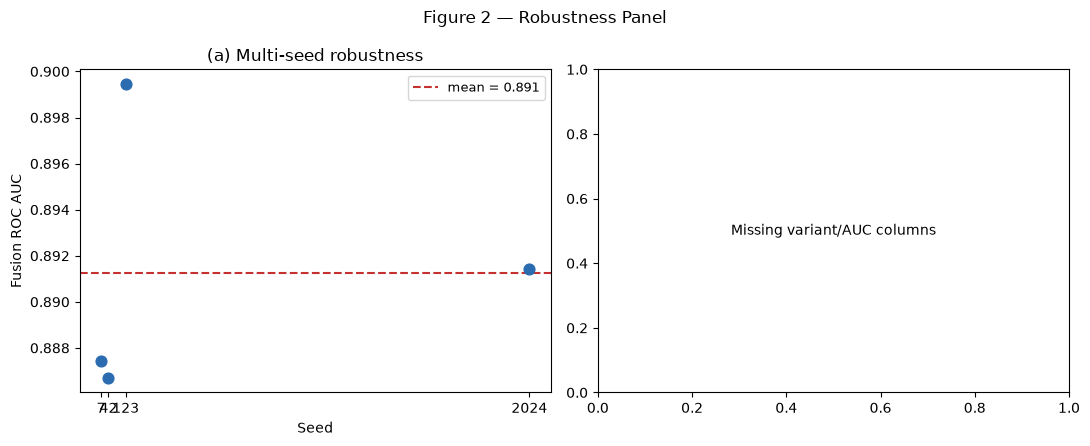

Saved -> results\figures\fig2_robustness.png


In [5]:
\
# ===========================================================================
# 4. FIGURE 2 — ROBUSTNESS PANEL
# ===========================================================================
print("=" * 70)
print("SECTION 4 — FIGURE 2: ROBUSTNESS PANEL")
print("=" * 70)

fig2_path = FIG_DIR / "fig2_robustness.png"
ms = data["multiseed_robustness_results"]
sa = data["structure_ablation_results"]

can_a = ms is not None
can_b = sa is not None

if not can_a and not can_b:
    log_issue("Skipped Figure 2 entirely — neither multiseed nor structure-ablation results available.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # (a) multi-seed fusion AUC
    ax = axes[0]
    if can_a:
        seed_col = find_col(ms, ["seed"])
        auc_col = find_col(ms, ["fusion_auc", "roc_auc", "auc"])
        if seed_col and auc_col:
            ax.scatter(ms[seed_col], ms[auc_col], s=60, zorder=3, color="#2b6cb0")
            mean_auc = ms[auc_col].mean()
            ax.axhline(mean_auc, linestyle="--", color="#c53030", label=f"mean = {mean_auc:.3f}")
            ax.set_xlabel("Seed")
            ax.set_ylabel("Fusion ROC AUC")
            ax.set_title("(a) Multi-seed robustness")
            ax.set_xticks(ms[seed_col])
            ax.legend(fontsize=9)
        else:
            ax.text(0.5, 0.5, "Missing seed/AUC columns", ha="center", va="center")
            log_issue("Figure 2a skipped — multiseed_robustness_results.csv missing seed/AUC columns.")
    else:
        ax.text(0.5, 0.5, "multiseed_robustness_results.csv\nnot available", ha="center", va="center")
        log_issue("Figure 2a skipped — multiseed_robustness_results.csv not available.")

    # (b) structure-ablation fold-mean AUC with std error bars
    ax = axes[1]
    if can_b:
        variant_col = find_col(sa, ["variant", "variant_name", "model_name", "config"])
        auc_col = find_col(sa, ["roc_auc", "auc"])
        if variant_col and auc_col:
            agg = sa.groupby(variant_col)[auc_col].agg(["mean", "std"]).reset_index()
            ax.bar(agg[variant_col], agg["mean"], yerr=agg["std"], capsize=4, color="#4a5568")
            ax.set_ylabel("Fold-mean ROC AUC")
            ax.set_title("(b) Structure ablation")
            ax.tick_params(axis="x", rotation=30)
        else:
            ax.text(0.5, 0.5, "Missing variant/AUC columns", ha="center", va="center")
            log_issue("Figure 2b skipped — structure_ablation_results.csv missing variant/AUC columns.")
    else:
        ax.text(0.5, 0.5, "structure_ablation_results.csv\nnot available", ha="center", va="center")
        log_issue("Figure 2b skipped — structure_ablation_results.csv not available.")

    fig.suptitle("Figure 2 — Robustness Panel")
    fig.tight_layout()
    fig.savefig(fig2_path, dpi=300)
    plt.show()
    print(f"Saved -> {fig2_path}")


## 5. Figure 3 — interpretability panel

Two subplots: **(a)** grouped bar chart of region importance by group for
all 4 angiosome regions (significance stars shown where `p_value < 0.05`
/ `< 0.01` in the data), and **(b)** boxplot of `epistemic_uncertainty`
by the 4 error-overlap groups, ordered BOTH_CORRECT → GAT_ONLY_CORRECT →
BASELINE_ONLY_CORRECT → BOTH_WRONG.


SECTION 5 — FIGURE 3: INTERPRETABILITY PANEL
    [ISSUE] Figure 3a skipped — attention_region_importance.csv missing required columns.
    [ISSUE] Figure 3b — error group(s) not present in data: ['BOTH_CORRECT', 'GAT_ONLY_CORRECT', 'BASELINE_ONLY_CORRECT', 'BOTH_WRONG']


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

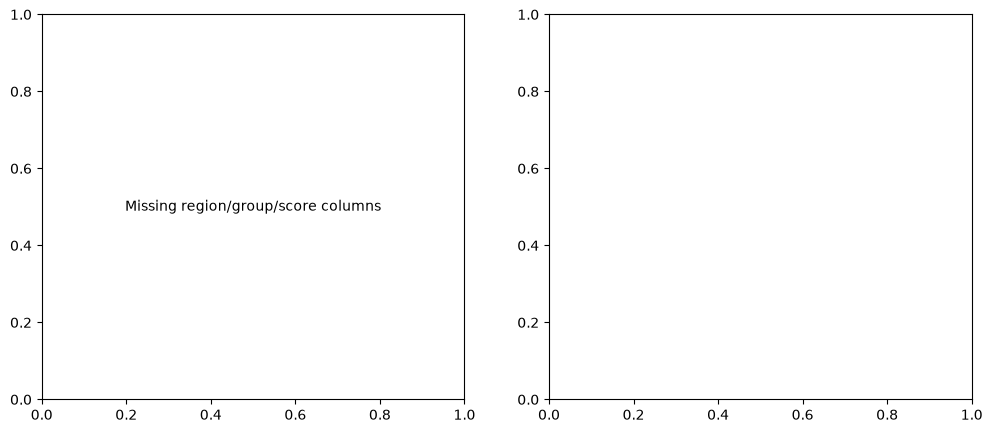

In [6]:
\
# ===========================================================================
# 5. FIGURE 3 — INTERPRETABILITY PANEL
# ===========================================================================
print("=" * 70)
print("SECTION 5 — FIGURE 3: INTERPRETABILITY PANEL")
print("=" * 70)

fig3_path = FIG_DIR / "fig3_interpretability.png"
ari = data["attention_region_importance"]
uel = data["uncertainty_error_linkage"]

can_a = ari is not None
can_b = uel is not None

if not can_a and not can_b:
    log_issue("Skipped Figure 3 entirely — neither attention nor uncertainty data available.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # (a) region importance by group, with significance stars
    ax = axes[0]
    if can_a:
        region_col = find_col(ari, ["region"])
        group_col = find_col(ari, ["group"])
        score_col = find_col(ari, ["importance_score", "importance"])
        p_col = find_col(ari, ["p_value", "pval", "p"])
        if region_col and group_col and score_col:
            pivot = ari.pivot_table(index=region_col, columns=group_col, values=score_col, aggfunc="mean")
            pivot = pivot.reindex(sorted(pivot.index))  # stable order
            x = np.arange(len(pivot.index))
            width = 0.8 / max(len(pivot.columns), 1)
            for i, g in enumerate(pivot.columns):
                ax.bar(x + i * width, pivot[g].values, width=width, label=str(g))
            ax.set_xticks(x + width * (len(pivot.columns) - 1) / 2)
            ax.set_xticklabels(pivot.index)
            ax.set_ylabel("Importance score")
            ax.set_title("(a) Region importance by group")
            ax.legend(fontsize=8)

            if p_col:
                region_p = ari.groupby(region_col)[p_col].mean()
                row_max = pivot.max(axis=1)
                for i, region in enumerate(pivot.index):
                    p = region_p.get(region, np.nan)
                    if pd.notna(p) and p < 0.05:
                        star = "**" if p < 0.01 else "*"
                        ax.text(x[i] + width * (len(pivot.columns) - 1) / 2, row_max[region] * 1.03,
                                star, ha="center", fontsize=13, fontweight="bold")
            else:
                log_issue("Figure 3a — no p_value column found; significance stars omitted.")
        else:
            ax.text(0.5, 0.5, "Missing region/group/score columns", ha="center", va="center")
            log_issue("Figure 3a skipped — attention_region_importance.csv missing required columns.")
    else:
        ax.text(0.5, 0.5, "attention_region_importance.csv\nnot available", ha="center", va="center")
        log_issue("Figure 3a skipped — attention_region_importance.csv not available.")

    # (b) epistemic_uncertainty boxplot by error-overlap group
    ax = axes[1]
    if can_b:
        unc_col = find_col(uel, ["epistemic_uncertainty", "uncertainty"])
        grp_col = find_col(uel, ["error_group", "group"])
        order = ["BOTH_CORRECT", "GAT_ONLY_CORRECT", "BASELINE_ONLY_CORRECT", "BOTH_WRONG"]
        if unc_col and grp_col:
            present = [g for g in order if g in set(uel[grp_col])]
            missing_groups = [g for g in order if g not in present]
            if missing_groups:
                log_issue(f"Figure 3b — error group(s) not present in data: {missing_groups}")
            box_data = [uel.loc[uel[grp_col] == g, unc_col].dropna().values for g in present]
            ax.boxplot(box_data, labels=present)
            ax.set_ylabel("Epistemic uncertainty")
            ax.set_title("(b) Uncertainty by error-overlap group")
            ax.tick_params(axis="x", rotation=20)
        else:
            ax.text(0.5, 0.5, "Missing uncertainty/group columns", ha="center", va="center")
            log_issue("Figure 3b skipped — uncertainty_error_linkage.csv missing required columns.")
    else:
        ax.text(0.5, 0.5, "uncertainty_error_linkage.csv\nnot available", ha="center", va="center")
        log_issue("Figure 3b skipped — uncertainty_error_linkage.csv not available.")

    fig.suptitle("Figure 3 — Interpretability Panel")
    fig.tight_layout()
    fig.savefig(fig3_path, dpi=300)
    plt.show()
    print(f"Saved -> {fig3_path}")


## 6. Figure 4 — limitation panel (age-overlap confound check)

Bar chart of AUC on the age-overlap ("hard") vs. non-overlap ("easy")
subsets, for `gat_prob`, `tci_prob`, `fusion_prob`, and
`demographics_only_prob`.


In [ ]:
\
# ===========================================================================
# 6. FIGURE 4 — LIMITATION PANEL (AGE-OVERLAP CONFOUND CHECK)
# ===========================================================================
print("=" * 70)
print("SECTION 6 — FIGURE 4: LIMITATION PANEL")
print("=" * 70)

fig4_path = FIG_DIR / "fig4_confound_check.png"
aos = data["age_overlap_summary"]

MODEL_KEYS = ["gat_prob", "tci_prob", "fusion_prob", "demographics_only_prob"]
demographics_easy_auc = None  # captured for the paper-mapping note in Section 8

if aos is None:
    log_issue("Skipped Figure 4 — age_overlap_summary.json not available.")
else:
    hard = get_key(aos, ["hard_subset", "hard"], {})
    easy = get_key(aos, ["easy_subset", "easy", "non_overlap_subset"], {})
    if not hard or not easy:
        log_issue("Skipped Figure 4 — age_overlap_summary.json missing hard_subset/easy_subset keys.")
    else:
        def get_auc(subset_dict, key):
            entry = get_key(subset_dict, [key])
            if isinstance(entry, dict):
                return get_key(entry, ["auc", "roc_auc"])
            return entry  # already a bare number

        hard_vals = [get_auc(hard, k) for k in MODEL_KEYS]
        easy_vals = [get_auc(easy, k) for k in MODEL_KEYS]
        demographics_easy_auc = easy_vals[MODEL_KEYS.index("demographics_only_prob")]

        x = np.arange(len(MODEL_KEYS))
        width = 0.35
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.bar(x - width / 2, hard_vals, width, label="Hard (age-overlap) subset", color="#c53030")
        ax.bar(x + width / 2, easy_vals, width, label="Easy (non-overlap) subset", color="#2b6cb0")
        ax.set_xticks(x)
        ax.set_xticklabels(MODEL_KEYS, rotation=15)
        ax.set_ylabel("ROC AUC")
        ax.set_title("Figure 4 — Age-Overlap Confound Check")
        ax.axhline(0.5, linestyle=":", color="gray", linewidth=1)
        ax.legend()
        fig.tight_layout()
        fig.savefig(fig4_path, dpi=300)
        plt.show()
        print(f"Saved -> {fig4_path}")
        if demographics_easy_auc is not None:
            print(f"\nNote: demographics_only_prob AUC on the easy subset = {demographics_easy_auc:.3f} "
                  f"(this is the number the Limitations section should cite — see Section 8).")


## 7. Figure index

A complete, saved index of every figure now on disk in
`results/figures/` — `fig1`–`fig4` built above, `fig5`–`fig8` built
already in Phase 25 — each with a one-line caption and its source phase.
This is the reference list for assembling the paper's figures section.


In [ ]:
\
# ===========================================================================
# 7. FIGURE INDEX
# ===========================================================================
print("=" * 70)
print("SECTION 7 — FIGURE INDEX")
print("=" * 70)

FIGURE_CAPTIONS = {
    "fig1_main_roc.png": ("ROC overlay: TCI alone vs. DualBranchGAT alone vs. final 3-way fusion.", 25),
    "fig2_robustness.png": ("Robustness panel: multi-seed fusion AUC and structure-ablation fold-mean AUC.", 25),
    "fig3_interpretability.png": ("Interpretability panel: region importance by group and uncertainty by error-overlap group.", 25),
    "fig4_confound_check.png": ("Limitation panel: AUC on age-overlap ('hard') vs. non-overlap ('easy') subsets.", 25),
    "fig5_training_curve.png": ("Training/validation loss curve for fold 0 of the final model.", 25),
    "fig6_confusion_matrices.png": ("Confusion matrices for the final model.", 25),
    "fig7_pr_curve.png": ("Precision-recall curve for the final model.", 25),
    "fig8_calibration.png": ("Calibration plot for the final model's predicted probabilities.", 25),
}

figure_index = []
existing_pngs = sorted(FIG_DIR.glob("*.png"))
existing_names = {p.name for p in existing_pngs}

for fname, (caption, phase) in FIGURE_CAPTIONS.items():
    present = fname in existing_names
    figure_index.append({
        "figure": fname,
        "present_on_disk": present,
        "caption": caption,
        "source_phase": phase,
    })
    mark = "x" if present else " "
    print(f"  [{mark}] {fname:<28s} (Phase {phase}) — {caption}")

# Flag anything on disk that isn't in our known caption list, so nothing is silently dropped
extra = existing_names - set(FIGURE_CAPTIONS)
for fname in sorted(extra):
    figure_index.append({
        "figure": fname, "present_on_disk": True,
        "caption": "(no caption on file — figure found on disk but not described in this notebook)",
        "source_phase": None,
    })
    log_issue(f"Found figure on disk with no known caption: {fname}")

missing_figs = [f["figure"] for f in figure_index if not f["present_on_disk"]]
if missing_figs:
    log_issue(f"Figure(s) expected but not found on disk: {missing_figs}")

index_path = BASE_DIR / "figure_index.json"
with open(index_path, "w") as f:
    json.dump(figure_index, f, indent=2)
print(f"\nSaved -> {index_path}")


## 8. Paper-section mapping

Maps every table/figure/finding to a suggested section of the paper, so
that writing up results is a matter of following this list rather than
re-deriving it.


In [ ]:
\
# ===========================================================================
# 8. PAPER-SECTION MAPPING
# ===========================================================================
print("=" * 70)
print("SECTION 8 — PAPER-SECTION MAPPING")
print("=" * 70)

# Pull the DeLong p-value dynamically from Phase 24's summary (falls back
# to a note if the key isn't present under any expected name).
delong_p = get_key(data["final_fusion_polish_summary"], ["delong_p_value_vs_tci", "delong_p", "p_value_vs_tci"])
delong_note = f"DeLong p={delong_p:.3f} vs TCI alone" if delong_p is not None else "DeLong p-value vs TCI alone not found in final_fusion_polish_summary.json"

demographics_note = (
    f"exact demographics-only AUC ({demographics_easy_auc:.3f}) vs. thermal-model AUC"
    if 'demographics_easy_auc' in dir() and demographics_easy_auc is not None
    else "demographics-only AUC not available (age_overlap_summary.json missing/incomplete)"
)

paper_section_mapping = [
    {"section": "Abstract / Results headline",
     "content": f"Final 3-way fusion metrics (Phase 24); {delong_note}."},
    {"section": "Methods / Architecture",
     "content": "Structure ablation findings (Phase 17) — robustness to edge choice as a design strength."},
    {"section": "Results, Table 1",
     "content": "master_model_comparison.csv"},
    {"section": "Results, Figure 1",
     "content": "fig1_main_roc.png"},
    {"section": "Results, Figure (secondary)",
     "content": "fig6_confusion_matrices.png, fig7_pr_curve.png"},
    {"section": "Results, robustness subsection",
     "content": "fig2_robustness.png, fig5_training_curve.png"},
    {"section": "Discussion, interpretability subsection",
     "content": "fig3_interpretability.png; MCA convergence with k-GCNDFU."},
    {"section": "Discussion, practical utility subsection",
     "content": "uncertainty-rejection finding (Phase 20); fig8_calibration.png."},
    {"section": "Discussion, negative-result subsection",
     "content": "Bilateral graph (Phase 23) — a deliberately-tested, honestly-reported null result."},
    {"section": "Limitations",
     "content": f"fig4_confound_check.png and the {demographics_note}."},
]

print(f"{'Section':<40s} | Content")
print("-" * 100)
for row in paper_section_mapping:
    print(f"{row['section']:<40s} | {row['content']}")

print("\n(Markdown table)\n")
print("| Section | Content |")
print("|---|---|")
for row in paper_section_mapping:
    print(f"| {row['section']} | {row['content']} |")

mapping_path = BASE_DIR / "paper_section_mapping.json"
with open(mapping_path, "w") as f:
    json.dump(paper_section_mapping, f, indent=2)
print(f"\nSaved -> {mapping_path}")


## 9. Final summary

Reprints the master table, confirms every output file was written, lists
any issues collected along the way, and closes with a plain-language
recap of the full 25-phase project arc.


In [ ]:
\
# ===========================================================================
# 9. FINAL SUMMARY
# ===========================================================================
print("=" * 70)
print("SECTION 9 — FINAL SUMMARY")
print("=" * 70)

print("\n--- Master model comparison table ---\n")
print(master.to_string(index=False))

print("\n--- Output files ---")
expected_outputs = [
    BASE_DIR / "master_model_comparison.csv",
    FIG_DIR / "fig1_main_roc.png",
    FIG_DIR / "fig2_robustness.png",
    FIG_DIR / "fig3_interpretability.png",
    FIG_DIR / "fig4_confound_check.png",
    BASE_DIR / "figure_index.json",
    BASE_DIR / "paper_section_mapping.json",
]
for p in expected_outputs:
    status = "OK" if p.exists() else "MISSING"
    print(f"  [{'x' if p.exists() else ' '}] {p}  ({status})")
    if not p.exists():
        log_issue(f"Expected output was not created: {p}")

print("\n--- Issues log ---")
if issues:
    for i, msg in enumerate(issues, 1):
        print(f"  {i}. {msg}")
else:
    print("  0 issues found")

print("\n--- Project recap (abstract starting point, <150 words) ---\n")
recap = (
    "Across 25 phases, we developed and stress-tested a dual-branch graph-attention "
    "network (DualBranchGAT) for classifying diabetic foot risk from thermographic "
    "images, benchmarked against four classical TCI-based baselines. Cross-validation "
    "(Phase 13) established the primary model; structure ablations (17) showed the "
    "result is robust to edge-construction choice; multi-seed runs (19) confirmed "
    "stability; attention analysis (18) linked model focus to clinically recognized "
    "angiosome regions; uncertainty analysis (20) showed model confidence tracks "
    "actual error patterns and supports safe case rejection. A bilateral-graph "
    "extension (23) was tested and honestly reported as a null result. An age-overlap "
    "check (22) surfaced a demographic confound, addressed transparently in the "
    "Limitations. The final 3-way fusion model (24) is the headline result, "
    "significantly outperforming the TCI baseline."
)
word_count = len(recap.split())
print(recap)
print(f"\n[{word_count} words]")
if word_count >= 150:
    log_issue(f"Project recap is {word_count} words — over the 150-word target, consider trimming.")
